# Perform single-cell quality control

In this notebook, we perform single-cell quality control using coSMicQC. We filter the single cells by identifying outliers with z-scores, and use either combinations of features or one feature for each condition. We use features from the AreaShape and Intensity modules to assess the quality of the segmented single-cells:

We process one cell line at a time.
We load the converted parquet file from every plate (time point) in the folder of the cell line with a glob and concatenate them into one data frame.
We identify outliers across all plates of the cell line together, since the z-scores are calculated from the whole data frame.

### Assessing poor nuclei segmentation

Due to high confluence with various seeding densities, sometimes nuclei overlap on top of each other, creating highly intense clusters within the Hoechst channel. 
To identify these nuclei, we use:

- **Nuclei mass displacement:** This metric quantifies how different the segmentation versus intensity based centeroids are, which can reflect multiple nuclei within one segmentation. 
- **Nuclei intensity:** This metric quantifies the total intensity of all pixels in a nucleus segmentation. 
In combination with abnormally high mass displacement, we detect nuclei that are also highly intense, likely indicating that this a group of overlapped nuclei.

For the preliminary dataset, we are working with cells that have not been treated so we do not expect any crazy phenotypes. Given that context, we can use a feature called Solidity. From ChatGPT, the simple explanation is that this features compares the area of the object to its convex hull, which measures compactness in relation to convexity. High solidity implies few indentations, while lower solidity indicates more irregularity.

- **Nuclei solidity:** This metric quantifies the compactness of the nuclei shape.
When a nuclei is mis-segmented, we see more protrusions or harsh outlines around the segmentations, which we expect this is what this feature will detect.

### Assessing poor cell segmentation

Also due to high confluence, overlapping nuclei can lead to the CellProfiler segmentation algorithm to sometimes keep bad segmentations (which is why we have coSMicQC) but can also detect these segmentations as being "too large" based on the parameters. 
This leads to poor cell segmentations because CellProfiler will remove the context of the nuclei it couldn't segment, leading to segmenting multiple cells as one cell and assigning it to one nuclei.
To identify these cells, we use:

- **Cell intensity in the nuclei channel:** This metric quantifies the total intensity of all pixels of a cell segmentation in the nuclei channel. We would expect fairly low total intensity in the nuclei channel for whole cells as there is only one 



In [1]:
import json
import os
import pathlib
import re
import sys
import time

# Ignore FutureWarnings from cytodataframe due to skimage deprecation (does not affect functionality)
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import yaml
from cosmicqc import find_outliers, label_outliers
from cytodataframe import CytoDataFrame
from IPython.display import HTML, display

sys.path.append("../utils")
from bandicoot_utils import bandicoot_check

warnings.filterwarnings("ignore", category=FutureWarning)


# Set functions for plotting and displaying outliers

### Function to plot scatterplot

In [2]:
def plot_cluster_nuclei_outliers(
    cell_line_df: pd.DataFrame,
    outliers_df: pd.DataFrame,
    cell_line: str,
    qc_fig_dir: pathlib.Path,
) -> None:
    """Plot scatterplot of the cluster nuclei outliers.

    Args:
        cell_line_df (pd.DataFrame): Dataframe of the CytoTable output with the morphology profiles.
        outliers_df (pd.DataFrame): Dataframe of the coSMicQC output which includes the identified outliers.
        cell_line (str): String of the cell line's name.
        qc_fig_dir (pathlib.Path): Path to the directory to save the plot.
    """
    # Create a copy of cell_line_df to avoid modifying the original
    cell_line_df = cell_line_df.copy()

    # Set the default 'Outlier_Status' to 'Single-cell passed QC'
    cell_line_df["Outlier_Status"] = "Single-cell passed QC"

    # Update 'Outlier_Status' for cells that failed QC
    cell_line_df.loc[cell_line_df.index.isin(outliers_df.index), "Outlier_Status"] = (
        "Single-cell failed QC"
    )

    # Create scatter plot
    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=cell_line_df,
        x="Nuclei_Intensity_MassDisplacement_DNA",
        y="Nuclei_Intensity_IntegratedIntensity_DNA",
        hue="Outlier_Status",
        palette={
            "Single-cell passed QC": "#006400",
            "Single-cell failed QC": "#990090",
        },
        alpha=0.2,
    )

    # Add threshold lines
    plt.axvline(
        x=outliers_df["Nuclei_Intensity_MassDisplacement_DNA"].min(),
        color="r",
        linestyle="--",
        label="Min. threshold for Nuclei Mass Displacement",
    )
    plt.axhline(
        y=outliers_df["Nuclei_Intensity_IntegratedIntensity_DNA"].min(),
        color="b",
        linestyle="--",
        label="Min. threshold for Nuclei Intensity",
    )

    # Customize plot
    plt.title(
        f"Nuclei Mass Displacement vs. Nuclei Integrated Intensity for {cell_line}"
    )
    plt.xlabel("Nuclei Mass Displacement (Hoechst)")
    plt.ylabel("Nuclei Integrated Intensity (Hoechst)")
    plt.tight_layout()

    # Show legend
    plt.legend(loc="upper right", bbox_to_anchor=(1.0, 1.0), prop={"size": 10})

    # Save figure without showing it
    plt.savefig(
        pathlib.Path(f"{qc_fig_dir}/{cell_line}_cluster_nuclei_outliers.png"), dpi=500
    )
    plt.close()  # Close the plot to prevent it from displaying


### Function to plot KDE

In [3]:
def plot_nuclei_solidity_histogram(
    cell_line_df: pd.DataFrame,
    outliers_df: pd.DataFrame,
    cell_line: str,
    qc_fig_dir: pathlib.Path,
) -> None:
    """Plot histogram of the nuclei solidity outliers.

    Args:
        cell_line_df (pd.DataFrame): Dataframe of the CytoTable output with the morphology profiles.
        outliers_df (pd.DataFrame): Dataframe of the coSMicQC output which includes the identified outliers.
        cell_line (str): String of the cell line's name.
        qc_fig_dir (pathlib.Path): Path to the directory to save the plot.
    """
    # Create a copy of cell_line_df to avoid modifying the original
    cell_line_df = cell_line_df.copy()

    # Set the default 'Outlier_Status' to 'Single-cell passed QC'
    cell_line_df["Outlier_Status"] = "Single-cell passed QC"

    # Update 'Outlier_Status' for cells that failed QC
    cell_line_df.loc[cell_line_df.index.isin(outliers_df.index), "Outlier_Status"] = (
        "Single-cell failed QC"
    )

    # Create histogram
    plt.figure(figsize=(10, 6))
    sns.histplot(
        data=cell_line_df,
        x="Nuclei_AreaShape_Solidity",
        hue="Outlier_Status",
        palette={
            "Single-cell passed QC": "#006400",
            "Single-cell failed QC": "#990090",
        },
        multiple="stack",  # Stacks bars based on hue
        bins=50,  # Number of bins
        kde=False,
    )

    # Add threshold line
    max_threshold = outliers_df["Nuclei_AreaShape_Solidity"].max()
    plt.axvline(
        x=max_threshold,
        color="r",
        linestyle="--",
        label=f"Threshold for Outliers: < {max_threshold}",
    )

    # Customize plot
    plt.ylabel("Count")
    plt.xlabel("Nuclei Solidity")
    plt.title(f"Distribution of Nuclei Solidity for {cell_line}")
    plt.legend()
    plt.tight_layout()

    # Save figure without showing it
    plt.savefig(
        pathlib.Path(
            f"{qc_fig_dir}/{cell_line}_nuclei_solidity_outliers_histogram.png"
        ),
        dpi=500,
    )
    plt.close()  # Close the plot to prevent it from displaying


### Function to display example outliers with outlines

In [4]:
def show_outlier_examples(
    outliers_df: pd.DataFrame,
    all_cells_df: pd.DataFrame,
    feature_thresholds: dict[str, float],
    compartment: str,
    n: int = 2,
    crop_offset: int | None = None,
) -> None:
    """Display the outliers closest to the cutoff from each plate (time point) with the segmentation outlines.

    We show the outliers that only just passed the thresholds, so we can see if the thresholds remove good quality cells.

    We display each plate on its own because the outline images are in a different folder per plate
    and the names of the original images are the same across plates.

    Args:
        outliers_df (pd.DataFrame): Dataframe of the coSMicQC output which includes the identified outliers.
        all_cells_df (pd.DataFrame): Dataframe with all single cells used to find the outliers (to calculate the z-scores).
        feature_thresholds (dict[str, float]): Thresholds (z-scores) of the QC condition for each feature.
        compartment (str): Compartment of the outlines to display (Nuclei or Cells).
        n (int): Number of example outliers closest to the cutoff to display per plate.
        crop_offset (int | None): Number of pixels to crop in each direction from the center of the object.
            If None, the image is cropped to the bounding box of the object.
    """
    # crop a fixed size box around the center of the object to see more of the area around it
    display_options = None
    if crop_offset is not None:
        display_options = {
            "offset_bounding_box": {
                "x_min": -crop_offset,
                "y_min": -crop_offset,
                "x_max": crop_offset,
                "y_max": crop_offset,
            },
            "brightness": 20,
        }

    # distance of each outlier past the cutoff of each feature (in z-scores), where the smallest distance across
    # the features is how close the outlier is to the cutoff (positive thresholds detect high values, negative low values)
    features = list(feature_thresholds)
    outliers_df = pd.DataFrame(outliers_df)
    all_cells_df = pd.DataFrame(all_cells_df)
    z_scores = (outliers_df[features] - all_cells_df[features].mean()) / all_cells_df[
        features
    ].std()
    cutoff_distance = pd.concat(
        [
            z_scores[feature] - threshold if threshold > 0 else threshold - z_scores[feature]
            for feature, threshold in feature_thresholds.items()
        ],
        axis=1,
    ).min(axis=1)
    outliers_df = outliers_df.assign(cutoff_distance=cutoff_distance)

    for plate, plate_outliers in outliers_df.groupby("Image_Metadata_Plate"):
        examples_df = plate_outliers.nsmallest(n, "cutoff_distance")

        # create an outline and orig mapping dictionary to map original images to outlines
        # note: we turn off formatting here to avoid the key-value pairing definition
        # from being reformatted by black, which is normally preferred.
        # fmt: off
        outline_to_orig_mapping = {
            rf"{compartment}Outlines_{plate}_{record['Image_Metadata_Well']}_{record['Image_Metadata_Site']}.tiff":
            rf"r{int(record['Image_Metadata_Row']):02d}c{int(record['Image_Metadata_Col']):02d}f{int(record['Image_Metadata_Site']):02d}p(\d{{2}})-ch\d+sk\d+fk\d+fl\d+\.tiff"
            for record in examples_df.to_dict(orient="records")
        }
        # fmt: on

        print(f"{plate}: {len(plate_outliers)} outliers (showing the {len(examples_df)} closest to the cutoff)")
        # MUST SET DATA AS DATAFRAME FOR OUTLINE DIR TO WORK
        examples_cdf = CytoDataFrame(
            data=pd.DataFrame(examples_df),
            data_outline_context_dir=f"{sqlite_dir}/{plate}_{cell_line}",
            segmentation_file_regex=outline_to_orig_mapping,
            display_options=display_options,
        )[features + ["Image_FileName_OrigDNA"]]

        if interactive_display:
            # interactive table with the brightness slider
            display(examples_cdf)
        else:
            # static HTML (debug=True) so the notebook does not stall when run with papermill
            # (set the text to black so it is readable on the light table background)
            display(
                HTML(
                    "<style>table.dataframe {color: #000000;}</style>"
                    + examples_cdf._repr_html_(debug=True)
                )
            )


## Set paths and variables

In [5]:
# Set parameter for papermill to use for processing (name of the cell line folder)
cell_line = "WPMY1"

# Show example outliers with the interactive widget (brightness slider) when running in a notebook
# Set to False when running with papermill (e.g., -p interactive_display False) as the widget can stall the run
interactive_display = True


In [6]:
# Find root directory of the project
root_dir = pathlib.Path().cwd()

image_base_dir = bandicoot_check(
    pathlib.Path(os.path.expanduser("~/mnt/bandicoot")).resolve(), root_dir
)

# Directory with the images (one folder per plate)
images_dir = pathlib.Path(f"{image_base_dir}/PCCMA_data/Atlas_v2_screen")

# Directory with one folder of CellProfiler outputs per job (<plate>_<cell_line>), which holds the outline images
sqlite_dir = pathlib.Path(f"{image_base_dir}/PCCMA_data/Atlas_v2_profiles/sqlite_outputs")

# Directory containing the converted profiles for the cell line (one parquet file per plate/time point)
data_dir = pathlib.Path(f"./data/converted_profiles/{cell_line}").resolve(strict=True)

# Directory to save qc figures
qc_fig_dir = pathlib.Path("./qc_figures")
qc_fig_dir.mkdir(exist_ok=True)

# Directory to save qc results
qc_results_dir = pathlib.Path("./qc_results")
qc_results_dir.mkdir(exist_ok=True)

# Load the thresholds (z-scores) for each QC condition: the defaults, replaced by any condition the cell line overrides
with open("qc_thresholds.yml") as file:
    thresholds_config = yaml.safe_load(file)

cell_line_overrides = (thresholds_config.get("cell_lines") or {}).get(cell_line, {})
unknown_conditions = set(cell_line_overrides) - set(thresholds_config["default"])
if unknown_conditions:
    raise ValueError(f"Unknown QC conditions for {cell_line}: {sorted(unknown_conditions)}")

qc_thresholds = {**thresholds_config["default"], **cell_line_overrides}
print(f"Thresholds for {cell_line} (overridden conditions: {sorted(cell_line_overrides) or 'none'}):")
print(json.dumps(qc_thresholds, indent=4))

# Set the compartment of choice to perform QC at the start (will change later)
compartment = "Nuclei"

# Number of pixels to crop in each direction from the center of a nucleus when displaying example outliers
# (larger than the nucleus bounding box so we can see the area around the nucleus)
nuclei_crop_offset = 50


Thresholds for WPMY1 (overridden conditions: ['clustered_nuclei', 'low_solidity_nuclei']):
{
    "clustered_nuclei": {
        "Nuclei_Intensity_MassDisplacement_DNA": 1.0,
        "Nuclei_Intensity_IntegratedIntensity_DNA": 1.5
    },
    "low_solidity_nuclei": {
        "Nuclei_AreaShape_Solidity": -3.0
    },
    "cells_multiple_nuclei": {
        "Cells_Intensity_IntegratedIntensity_DNA": 3.0
    }
}


## Load in all plates of the cell line to perform QC on

In [7]:
start_time = time.time()  # Start timer for loading

# Find the parquet file for every plate (time point) of the cell line
parquet_paths = sorted(data_dir.glob("*_converted.parquet"))
assert parquet_paths, f"No parquet files found for {cell_line}"

# Load and concatenate all plates (reset the index so every single cell has a unique index)
cell_line_df = pd.concat(
    [pd.read_parquet(path, engine="pyarrow") for path in parquet_paths],
    ignore_index=True,
)

end_time = time.time()  # End timer for loading
print(
    f"Loaded {len(parquet_paths)} plates for {cell_line}, Shape: {cell_line_df.shape}, Time taken: {end_time - start_time:.2f} seconds"
)
print(cell_line_df["Image_Metadata_Plate"].value_counts().sort_index())


Loaded 3 plates for WPMY1, Shape: (10210, 2488), Time taken: 0.66 seconds
Image_Metadata_Plate
BR00150701    5091
BR00150702    4662
BR00150703     457
Name: count, dtype: int64


## Correct all columns with PathName to have the correct parent path

When ran on HPC, the path will reflect that of the HPC and not local when we are processing this data.

In [8]:
for col in cell_line_df.columns:
    if "PathName" in col and "Illum" not in col:
        cell_line_df[col] = cell_line_df[col].apply(
            lambda x: (
                re.sub(r"^.*PCCMA_atlas_data/", f"{images_dir}/", x)
                if isinstance(x, str)
                else x
            )
        )

# Print example image path after fix
print(cell_line_df["Image_PathName_OrigDNA"].dropna().iloc[0])


/home/jenna/mnt/bandicoot/PCCMA_data/Atlas_v2_screen/BR00150701__2026-07-02T18_25_42-Measurement 1/Images


## Reduce down the columns to the features to be used for QC and metadata (improves speed)

In [9]:
# metadata columns to include in output data frame
metadata_columns = [
    "Image_Metadata_Plate",
    "Image_Metadata_Well",
    "Image_Metadata_Site",
    "Image_Metadata_Row",
    "Image_Metadata_Col",
    f"Metadata_{compartment}_Location_Center_X",
    f"Metadata_{compartment}_Location_Center_Y",
    "Image_FileName_OrigDNA",
    "Image_FileName_OrigAGP",
    "Image_PathName_OrigDNA",
    "Image_PathName_OrigAGP",
    f"{compartment}_AreaShape_BoundingBoxMaximum_X",
    f"{compartment}_AreaShape_BoundingBoxMaximum_Y",
    f"{compartment}_AreaShape_BoundingBoxMinimum_X",
    f"{compartment}_AreaShape_BoundingBoxMinimum_Y",
]

# Define the QC features
qc_features = [
    "Nuclei_Intensity_IntegratedIntensity_DNA",
    "Nuclei_AreaShape_Solidity",
    "Nuclei_Intensity_MassDisplacement_DNA",
]

# Filter cell_line_df to only include metadata columns and QC features
filtered_df = cell_line_df[metadata_columns + qc_features]


## Detect segmentations of clustered nuclei

Number of outliers: 209 (2.05%)
Outliers Range:
Nuclei_Intensity_MassDisplacement_DNA Min: 0.8858501166724965
Nuclei_Intensity_MassDisplacement_DNA Max: 6.711670577550498
Nuclei_Intensity_IntegratedIntensity_DNA Min: 115.59966976195574
Nuclei_Intensity_IntegratedIntensity_DNA Max: 958.2403874360025
(209, 17)
BR00150701: 122 outliers (showing the 2 closest to the cutoff)


,Nuclei_Intensity_MassDisplacement_DNA,Nuclei_Intensity_IntegratedIntensity_DNA,Image_FileName_OrigDNA
4161,0.995982,115.599670,
4399,1.076304,115.639633,

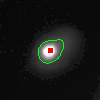
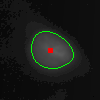

BR00150702: 52 outliers (showing the 2 closest to the cutoff)


,Nuclei_Intensity_MassDisplacement_DNA,Nuclei_Intensity_IntegratedIntensity_DNA,Image_FileName_OrigDNA
8309,2.000054,116.627436,
8207,2.677598,116.696625,

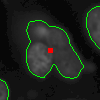
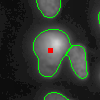

BR00150703: 35 outliers (showing the 2 closest to the cutoff)


,Nuclei_Intensity_MassDisplacement_DNA,Nuclei_Intensity_IntegratedIntensity_DNA,Image_FileName_OrigDNA
9879,0.885850,127.825602,
9959,1.554143,117.479047,

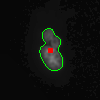
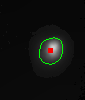

In [10]:
# Find large nuclei outliers for the current cell line
nuclei_clustered_outliers = find_outliers(
    df=filtered_df,
    metadata_columns=metadata_columns,
    feature_thresholds=qc_thresholds["clustered_nuclei"],
)

print(nuclei_clustered_outliers.shape)
show_outlier_examples(
    outliers_df=nuclei_clustered_outliers,
    all_cells_df=filtered_df,
    feature_thresholds=qc_thresholds["clustered_nuclei"],
    compartment=compartment,
    crop_offset=nuclei_crop_offset,
)


### Plot the outliers

In [11]:
# Save cluster nuclei scatterplot
plot_cluster_nuclei_outliers(
    cell_line_df=cell_line_df,
    outliers_df=nuclei_clustered_outliers,
    cell_line=cell_line,
    qc_fig_dir=qc_fig_dir,
)


## Detect very irregular shaped nuclei, likely indicating mis-segmentation

**NOTE:** For the pilot data, we are determining optimal conditions (seeding density and time point). This means all cells are not treated and should be in a "healthy" state. Given that `solidity` measures how irregular the shape of a nuclei is, we would expect that cells treated with a drug/compound could yield interesting shapes or phenotypes. Since we are not working with drug treatments at this time, we can use this feature to identify technically incorrect segmentations.

Number of outliers: 195 (1.91%)
Outliers Range:
Nuclei_AreaShape_Solidity Min: 0.735
Nuclei_AreaShape_Solidity Max: 0.9025974025974026
(195, 16)
BR00150701: 117 outliers (showing the 2 closest to the cutoff)


,Nuclei_AreaShape_Solidity,Image_FileName_OrigDNA
1765,0.902597,
158,0.902574,

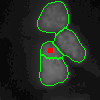
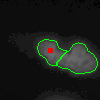

BR00150702: 66 outliers (showing the 2 closest to the cutoff)


,Nuclei_AreaShape_Solidity,Image_FileName_OrigDNA
5256,0.902198,
9502,0.902033,

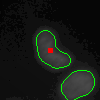
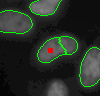

BR00150703: 12 outliers (showing the 2 closest to the cutoff)


,Nuclei_AreaShape_Solidity,Image_FileName_OrigDNA
9879,0.900125,
9950,0.895623,

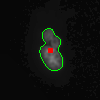
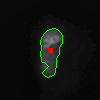

In [12]:
# Find low nuclei solidity outliers for the current cell line
solidity_nuclei_outliers = find_outliers(
    df=filtered_df,
    metadata_columns=metadata_columns,
    feature_thresholds=qc_thresholds["low_solidity_nuclei"],
)

print(solidity_nuclei_outliers.shape)
show_outlier_examples(
    outliers_df=solidity_nuclei_outliers,
    all_cells_df=filtered_df,
    feature_thresholds=qc_thresholds["low_solidity_nuclei"],
    compartment=compartment,
    crop_offset=nuclei_crop_offset,
)


### Plot the outliers

In [13]:
# Save low nuclei solidity histogram
plot_nuclei_solidity_histogram(
    cell_line_df=cell_line_df,
    outliers_df=solidity_nuclei_outliers,
    cell_line=cell_line,
    qc_fig_dir=qc_fig_dir,
)


## Detect cells that contain multiple nuclei due to segmentation issues

When CellProfiler segments a cluster of nuclei and decides that it is over the diameter range as specified in the parameters, it will not include that segmentation when segmenting whole cells. 
This can lead to a whole cell segmentation based on one nuclei including the adjacent nuclei that was not included as a segmentation.

This description requires prior knowledge of the `IdentifyPrimaryObjects` and `IdentifySecondaryObjects` modules.

As a metaphor, we can think of it as three apples on a plate.
One apple is detected correctly as one apple, but the other two were two close together, detected as one apple, and then removed from the plate because of it.
Now, it looks like the whole plate belongs to the one correct apple, but in reality the plate should be split between three apples.
This is the problem we want to avoid for a single-cell segmentation, we don't want to have a whole cell segmentation be assigned to one nuclei when it actually contains multiple nuclei.


In [14]:
# change compartment to cells
compartment = "Cells"

# metadata columns to include in output data frame
metadata_columns = [
    "Image_Metadata_Plate",
    "Image_Metadata_Well",
    "Image_Metadata_Site",
    "Image_Metadata_Row",
    "Image_Metadata_Col",
    f"Metadata_{compartment}_Location_Center_X",
    f"Metadata_{compartment}_Location_Center_Y",
    "Image_FileName_OrigDNA",
    "Image_FileName_OrigAGP",
    "Image_PathName_OrigDNA",
    "Image_PathName_OrigAGP",
    f"{compartment}_AreaShape_BoundingBoxMaximum_X",
    f"{compartment}_AreaShape_BoundingBoxMaximum_Y",
    f"{compartment}_AreaShape_BoundingBoxMinimum_X",
    f"{compartment}_AreaShape_BoundingBoxMinimum_Y",
]

# Define the QC features
qc_features = ["Cells_Intensity_IntegratedIntensity_DNA", "Cytoplasm_Intensity_IntegratedIntensity_DNA", "Cells_AreaShape_Area"]

# Filter cell_line_df to only include metadata columns and QC features
filtered_df = cell_line_df[metadata_columns + qc_features]


### Detect cell outliers

Number of outliers: 54 (0.53%)
Outliers Range:
Cells_Intensity_IntegratedIntensity_DNA Min: 257.30845970101655
Cells_Intensity_IntegratedIntensity_DNA Max: 3671.5869308849797
(54, 16)
BR00150701: 21 outliers (showing the 2 closest to the cutoff)


,Cells_Intensity_IntegratedIntensity_DNA,Image_FileName_OrigDNA
2933,257.308460,
685,260.800855,

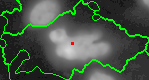
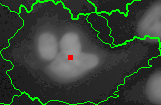

BR00150702: 13 outliers (showing the 2 closest to the cutoff)


,Cells_Intensity_IntegratedIntensity_DNA,Image_FileName_OrigDNA
6812,264.701048,
6478,269.009653,

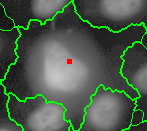
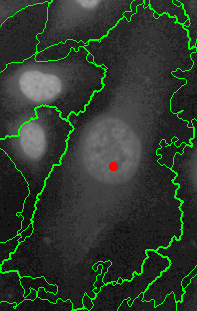

BR00150703: 20 outliers (showing the 2 closest to the cutoff)


,Cells_Intensity_IntegratedIntensity_DNA,Image_FileName_OrigDNA
9928,270.103801,
9940,278.612429,

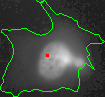
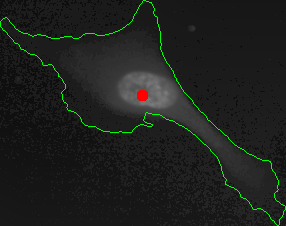

In [15]:
# Find cell outliers for the current cell line
cell_outliers = find_outliers(
    df=filtered_df,
    metadata_columns=metadata_columns,
    feature_thresholds=qc_thresholds["cells_multiple_nuclei"],
)

print(cell_outliers.shape)
show_outlier_examples(
    outliers_df=cell_outliers,
    all_cells_df=filtered_df,
    feature_thresholds=qc_thresholds["cells_multiple_nuclei"],
    compartment=compartment,
)


## Save the QC annotations

We label every single cell with the outcome of each QC condition using `label_outliers` from coSMicQC and save the labels as a QC annotations file for the cell line.
We do not save a copy of the profiles, since the converted profiles are already one file per plate.
In bulk and single-cell processing, we load the converted profiles of a plate and merge the QC annotations on the plate, image number, and object number to remove the outliers.

In [16]:
# metadata columns that identify each single cell (to merge the annotations with the converted profiles)
annotation_metadata_columns = [
    "Image_Metadata_Plate",
    "Image_Metadata_Well",
    "Image_Metadata_Site",
    "Metadata_ImageNumber",
    "Metadata_Nuclei_Number_Object_Number",
    "Metadata_Cells_Number_Object_Number",
]

# features used across all QC conditions
all_qc_features = sorted(
    {feature for thresholds in qc_thresholds.values() for feature in thresholds}
)

# Label the outliers of each condition (Metadata_cqc_<condition>_is_outlier) and save as an annotations file
qc_annotations_df = label_outliers(
    df=cell_line_df[annotation_metadata_columns + all_qc_features],
    feature_thresholds=qc_thresholds,
    export_path=f"{qc_results_dir}/{cell_line}_qc_annotations.parquet",
    export_as_annotations=True,
    annotation_metadata_columns=annotation_metadata_columns,
)

# Save the thresholds used for the cell line next to the QC annotations
with open(f"{qc_results_dir}/{cell_line}_qc_thresholds.json", "w") as file:
    json.dump(qc_thresholds, file, indent=4)

# Print the number of single cells that failed each condition and any condition
outlier_columns = [col for col in qc_annotations_df.columns if col.endswith("_is_outlier")]
print(qc_annotations_df[outlier_columns].sum())

failed = qc_annotations_df[outlier_columns].any(axis=1)
print(
    f"Total failing single cells: {failed.sum()} of {len(failed)} ({failed.mean() * 100:.2f}%)"
)


Metadata_cqc_clustered_nuclei_is_outlier         209
Metadata_cqc_low_solidity_nuclei_is_outlier      195
Metadata_cqc_cells_multiple_nuclei_is_outlier     54
dtype: int64
Total failing single cells: 389 of 10210 (3.81%)
